<a href="https://colab.research.google.com/github/Bloop15/Machine-Learning--II/blob/main/Bagging_and_Boosting_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

df["Diagnosis"] = cancer.target

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
X = df.drop("Diagnosis", axis=1)
y = df["Diagnosis"]

print("Number of features:", X.shape[1])
print("Number of samples:", X.shape[0])

print("\nDiagnosis distribution:")
print(y.value_counts())

print("\nMalignant cases:", (y == 0).sum())
print("Benign cases:", (y == 1).sum())

Number of features: 30
Number of samples: 569

Diagnosis distribution:
Diagnosis
1    357
0    212
Name: count, dtype: int64

Malignant cases: 212
Benign cases: 357


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 455
Testing samples: 114

Training class distribution:
Diagnosis
1    285
0    170
Name: count, dtype: int64

Testing class distribution:
Diagnosis
1    72
0    42
Name: count, dtype: int64


In [5]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42
)

bagging_model.fit(X_train, y_train)

print("Bagging model trained successfully!")

Bagging model trained successfully!


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_pred_bagging = bagging_model.predict(X_test)

print("BAGGING CLASSIFIER RESULTS")
print("=" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred_bagging), 4))
print("Precision:", round(precision_score(y_test, y_pred_bagging), 4))
print("Recall:", round(recall_score(y_test, y_pred_bagging), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_bagging), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_bagging,
    target_names=["Malignant", "Benign"]
))

BAGGING CLASSIFIER RESULTS
Accuracy: 0.9386
Precision: 0.9452
Recall: 0.9583
F1-Score: 0.9517

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.93      0.90      0.92        42
      Benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



In [7]:
from sklearn.ensemble import AdaBoostClassifier

adaboost_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

adaboost_model.fit(X_train, y_train)

print("AdaBoost model trained successfully!")

AdaBoost model trained successfully!


In [8]:
y_pred_adaboost = adaboost_model.predict(X_test)

print("ADABOOST CLASSIFIER RESULTS")
print("=" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred_adaboost), 4))
print("Precision:", round(precision_score(y_test, y_pred_adaboost), 4))
print("Recall:", round(recall_score(y_test, y_pred_adaboost), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_adaboost), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_adaboost,
    target_names=["Malignant", "Benign"]
))

ADABOOST CLASSIFIER RESULTS
Accuracy: 0.9561
Precision: 0.9467
Recall: 0.9861
F1-Score: 0.966

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.97      0.90      0.94        42
      Benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [9]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gradient_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [10]:
y_pred_gradient = gradient_model.predict(X_test)

print("GRADIENT BOOSTING CLASSIFIER RESULTS")
print("=" * 45)

print("Accuracy:", round(accuracy_score(y_test, y_pred_gradient), 4))
print("Precision:", round(precision_score(y_test, y_pred_gradient), 4))
print("Recall:", round(recall_score(y_test, y_pred_gradient), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_gradient), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_gradient,
    target_names=["Malignant", "Benign"]
))

GRADIENT BOOSTING CLASSIFIER RESULTS
Accuracy: 0.9561
Precision: 0.9467
Recall: 0.9861
F1-Score: 0.966

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.97      0.90      0.94        42
      Benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



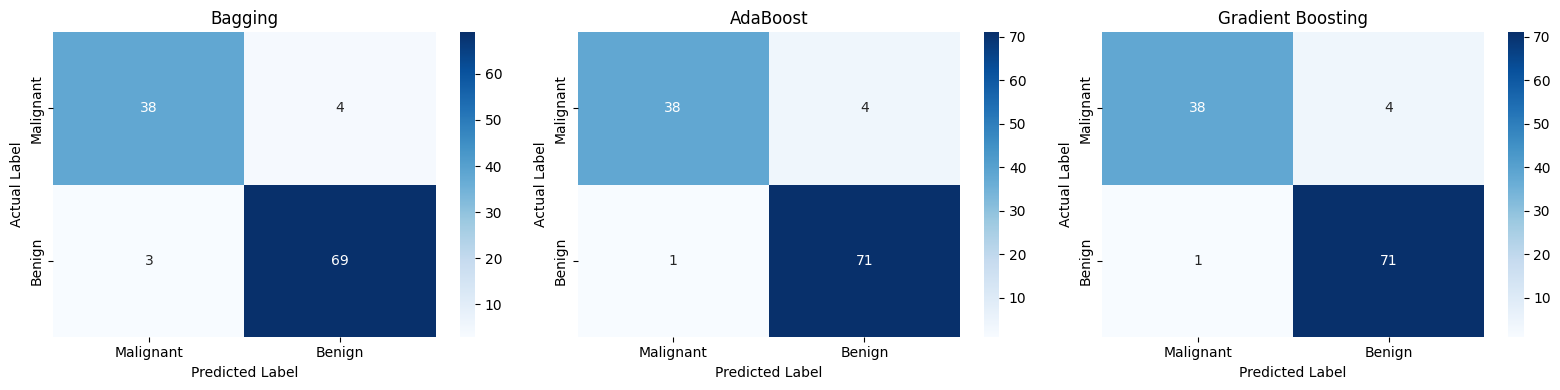

In [11]:
from sklearn.metrics import confusion_matrix

models = {
    "Bagging": y_pred_bagging,
    "AdaBoost": y_pred_adaboost,
    "Gradient Boosting": y_pred_gradient
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, predictions) in zip(axes, models.items()):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Malignant", "Benign"],
        yticklabels=["Malignant", "Benign"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [12]:
results = {
    "Model": ["Bagging", "AdaBoost", "Gradient Boosting"],

    "Accuracy": [
        accuracy_score(y_test, y_pred_bagging),
        accuracy_score(y_test, y_pred_adaboost),
        accuracy_score(y_test, y_pred_gradient)
    ],

    "Precision": [
        precision_score(y_test, y_pred_bagging),
        precision_score(y_test, y_pred_adaboost),
        precision_score(y_test, y_pred_gradient)
    ],

    "Recall": [
        recall_score(y_test, y_pred_bagging),
        recall_score(y_test, y_pred_adaboost),
        recall_score(y_test, y_pred_gradient)
    ],

    "F1-Score": [
        f1_score(y_test, y_pred_bagging),
        f1_score(y_test, y_pred_adaboost),
        f1_score(y_test, y_pred_gradient)
    ]
}

comparison_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
print("=" * 45)

display(comparison_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Bagging,0.9386,0.9452,0.9583,0.9517
1,AdaBoost,0.9561,0.9467,0.9861,0.9660
2,Gradient Boosting,0.9561,0.9467,0.9861,0.9660


In [13]:
print("MALIGNANT CLASS PERFORMANCE")
print("=" * 45)

print("Bagging Malignant Recall:",
      round(recall_score(y_test, y_pred_bagging, pos_label=0), 4))

print("AdaBoost Malignant Recall:",
      round(recall_score(y_test, y_pred_adaboost, pos_label=0), 4))

print("Gradient Boosting Malignant Recall:",
      round(recall_score(y_test, y_pred_gradient, pos_label=0), 4))

MALIGNANT CLASS PERFORMANCE
Bagging Malignant Recall: 0.9048
AdaBoost Malignant Recall: 0.9048
Gradient Boosting Malignant Recall: 0.9048


In [14]:
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 50)

print("Dataset: Breast Cancer Wisconsin Diagnostic")
print("Total samples:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nModels Evaluated:")
print("1. Bagging Classifier")
print("2. AdaBoost Classifier")
print("3. Gradient Boosting Classifier")

print("\nBest Test Accuracy: 95.61%")
print("Best Models: AdaBoost and Gradient Boosting")

print("\nMalignant Recall:")
print("Bagging: 90.48%")
print("AdaBoost: 90.48%")
print("Gradient Boosting: 90.48%")

print("\nConclusion:")
print("AdaBoost and Gradient Boosting achieved the highest")
print("accuracy and F1-score on the test dataset.")
print("All three models achieved the same malignant recall.")

EXPERIMENT COMPLETED SUCCESSFULLY
Dataset: Breast Cancer Wisconsin Diagnostic
Total samples: 569
Training samples: 455
Testing samples: 114

Models Evaluated:
1. Bagging Classifier
2. AdaBoost Classifier
3. Gradient Boosting Classifier

Best Test Accuracy: 95.61%
Best Models: AdaBoost and Gradient Boosting

Malignant Recall:
Bagging: 90.48%
AdaBoost: 90.48%
Gradient Boosting: 90.48%

Conclusion:
AdaBoost and Gradient Boosting achieved the highest
accuracy and F1-score on the test dataset.
All three models achieved the same malignant recall.
